# The data at a glance

This notebook is the data overview for Milestone 1: what the two datasets cover, how the daily
"true variance" is distributed, and three facts about it that every model in the thesis leans on.
It mirrors `notes/data_overview.py` (the script that produces the numbers on the overview slides)
with the explanations written out and the charts shown inline.

**What we look at.**

- The **VOLARE panel** built in `data_preparation_tutorial.ipynb`: 40 stocks, one row per stock
  and trading day from 2015 to 2026, each row carrying the day's return and its true variance
  `rv_target` (decisions 2 and 3 applied).
- The **M6 competition data**: the 100 assets of the competition and the teams' submissions, used
  later for the replication of the winning methods.

**The route.**
1. Coverage of the two datasets
2. Summary statistics of the daily truth
3. Variance is persistent, returns are not
4. One market-wide level of risk
5. The cross-section: calm and wild stocks
6. The numbers file

**How to use it.** Run the cells from the top with the `.venv` kernel. The charts are saved to
`notes/figures/overview_*.png` and the last cell writes `notes/figures/data_overview_numbers.json`,
the file the slide builder reads. It needs `data/processed/panel.parquet` (`make panel`) and the M6
files in `data/raw/m6/` (`python -m thesis.data.download_m6`).

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from thesis.paths import PANEL, RAW_M6

FIG = ROOT / "notes" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)
numbers = {}   # every number quoted on the overview slides, saved at the end

# chart style: three colours checked for colour-blind safety, quiet solid grid, dark text
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "figure.dpi": 110,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE})


def tidy(ax, title, subtitle=None):
    ax.set_title(title, loc="left", color=INK, fontsize=11.5, fontweight="bold", pad=26 if subtitle else 8)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                    color=MUTED, fontsize=9.5)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")


def ann_vol(variance):
    # daily variance -> yearly volatility in percent (252 trading days in a year)
    return 100 * np.sqrt(252 * variance)


p = pd.read_parquet(PANEL).sort_values(["symbol", "date"]).reset_index(drop=True)
print(f"panel: {len(p):,} rows x {p.shape[1]} columns")
print("columns:", ", ".join(p.columns))
p.head(3)

panel: 117,280 rows x 41 columns
columns: date, symbol, volume, trades, volare_open, volare_close, volare_high, volare_low, pr, gkr, rr5, rv1, rv5, rv5_ss, bv5, bv5_ss, rsp5, rsn5, rsp5_ss, rsn5_ss, medrv5, minrv5, rk, rq5, rq5_ss, open, close, adj_close, yahoo_volume, dividend, split, ret, ret_overnight, ret_intraday, vix, mkt_ret, earnings_afterclose, rv_intraday_used, rv_target, log_rv_target, mkt_rv


,date,symbol,volume,trades,volare_open,volare_close,volare_high,volare_low,pr,gkr,rr5,rv1,rv5,rv5_ss,bv5,bv5_ss,rsp5,rsn5,rsp5_ss,rsn5_ss,...,minrv5,rk,rq5,rq5_ss,open,close,adj_close,yahoo_volume,dividend,split,ret,ret_overnight,ret_intraday,vix,mkt_ret,earnings_afterclose,rv_intraday_used,rv_target,log_rv_target,mkt_rv
0,2015-01-02,AAPL,52510449,286295,111.3973,109.24,111.47,107.35,0.000512,0.000561,0.000331,0.000275,0.000422,0.000347,0.000364,0.000312,0.000102,0.000320,0.000089,0.000258,...,0.000365,0.000291,9.045224e-07,5.234818e-07,27.8475,27.332500,24.171757,212818400,0.0,0.0,-0.009558,0.009109,-0.018667,17.790001,-0.000677,False,0.000347,0.000430,-7.751472,0.000142
1,2015-01-05,AAPL,60727778,316713,108.2914,106.38,108.65,105.41,0.000331,0.000336,0.000252,0.000278,0.000326,0.000224,0.000343,0.000240,0.000124,0.000202,0.000084,0.000140,...,0.000365,0.000220,2.405967e-07,1.006578e-07,27.0725,26.562500,23.490803,257142000,0.0,0.0,-0.028576,-0.009558,-0.019018,19.920000,-0.017715,False,0.000224,0.000316,-8.060769,0.000142
2,2015-01-06,AAPL,64865433,362762,106.4644,106.30,107.42,104.63,0.000250,0.000345,0.000389,0.000370,0.000474,0.000439,0.000525,0.000417,0.000230,0.000244,0.000201,0.000238,...,0.000576,0.000341,1.825222e-07,1.929761e-07,26.6350,26.565001,23.493011,263188400,0.0,0.0,0.000094,0.002726,-0.002632,21.120001,-0.009051,False,0.000439,0.000446,-7.714983,0.000222


---
## 1. Coverage of the two datasets

The panel is **balanced**: every stock has every trading day, so the row count is exactly
stocks x days. The M6 file `assets_m6.csv` holds the daily prices of the 100 competition assets
over the twelve monthly rounds (February 2022 to February 2023); `ijf_submissions.csv` holds every
team's submitted forecast in every round (plus the trial run before round 1), one row per team,
round and asset. Not every team submitted in every round, so the row count is well below
teams x rounds x assets.

In [2]:
m6 = pd.read_csv(RAW_M6 / "assets_m6.csv")
sub = pd.read_csv(RAW_M6 / "ijf_submissions.csv", usecols=["Team", "Submission", "IsActive"])

numbers.update(n_rows=len(p), n_stocks=p.symbol.nunique(), n_days=p.date.nunique(),
               start=str(p.date.min().date()), end=str(p.date.max().date()),
               m6_assets=int(m6.symbol.nunique()), m6_start=str(pd.to_datetime(m6.date).min().date()),
               m6_end=str(pd.to_datetime(m6.date).max().date()), m6_rows=len(m6),
               m6_teams=int(sub.Team.nunique()), m6_submission_rows=len(sub))

coverage = pd.DataFrame({
    "rows": [numbers["n_rows"], numbers["m6_rows"], numbers["m6_submission_rows"]],
    "units": [f'{numbers["n_stocks"]} stocks x {numbers["n_days"]:,} days',
              f'{numbers["m6_assets"]} assets, daily prices',
              f'{numbers["m6_teams"]} teams; 12 rounds plus a trial run; {numbers["m6_assets"]} assets per submission'],
    "from": [numbers["start"], numbers["m6_start"], ""],
    "to": [numbers["end"], numbers["m6_end"], ""],
}, index=["VOLARE panel (data/processed/panel.parquet)", "M6 asset prices (assets_m6.csv)",
          "M6 submissions (ijf_submissions.csv)"])
print(f"balanced panel: {numbers['n_rows'] == numbers['n_stocks'] * numbers['n_days']}")
coverage

balanced panel: True


,rows,units,from,to
VOLARE panel (data/processed/panel.parquet),117280,"40 stocks x 2,932 days",2015-01-02,2026-08-31
M6 asset prices (assets_m6.csv),26446,"100 assets, daily prices",2022-01-31,2023-02-17
M6 submissions (ijf_submissions.csv),275200,251 teams; 12 rounds plus a trial run; 100 assets per submission,,


---
## 2. Summary statistics of the daily truth

`rv_target` is a daily **variance**. To read it, take the square root and scale to a year
(x sqrt 252): that is the yearly volatility traders quote, and the unit used in every chart below.
The distribution is wide and right-skewed: a typical day sits near 20 percent, one day in a hundred
above 100 percent, and the single worst day (Netflix's results in April 2022) above 500 percent.

The three counts at the end are the special days from the data preparation: after-close earnings
nights (decision 3), ex-dividend days (the dividend-aware overnight return) and stock splits.

In [3]:
vol = ann_vol(p.rv_target)
q = vol.quantile([0.01, 0.1, 0.5, 0.9, 0.99])
by_stock = p.groupby("symbol").rv_target.median().pipe(ann_vol).sort_values()
worst = p.loc[p.ret.idxmin()]

numbers.update(vol_p01=float(q[0.01]), vol_p10=float(q[0.1]), vol_med=float(q[0.5]), vol_p90=float(q[0.9]),
               vol_p99=float(q[0.99]), vol_max=float(vol.max()),
               calm_stock=by_stock.index[0], calm_vol=float(by_stock.iloc[0]),
               wild_stock=by_stock.index[-1], wild_vol=float(by_stock.iloc[-1]),
               ret_med_abs=float(100 * p.ret.abs().median()), ret_max=float(100 * p.ret.min()),
               ret_max_sym=worst["symbol"], ret_max_date=str(worst["date"].date()),
               vix_med=float(p.vix.median()), vix_max=float(p.vix.max()),
               n_flag=int(p.earnings_afterclose.sum()), n_exdiv=int((p.dividend.fillna(0) > 0).sum()),
               n_splits=int((p.split.fillna(0) > 0).sum()))

quantiles = pd.DataFrame({"daily truth as yearly vol %": [q[0.01], q[0.1], q[0.5], q[0.9], q[0.99], vol.max()]},
                         index=["1st percentile", "10th", "median", "90th", "99th", "maximum"]).round(1)
print(f"calmest stock {numbers['calm_stock']} at {numbers['calm_vol']:.0f}%, "
      f"wildest {numbers['wild_stock']} at {numbers['wild_vol']:.0f}% (median day)")
print(f"median |daily return| {numbers['ret_med_abs']:.2f}%; largest daily return "
      f"{numbers['ret_max_sym']} {numbers['ret_max']:.0f}% on {numbers['ret_max_date']}")
print(f"VIX: median {numbers['vix_med']:.0f}, maximum {numbers['vix_max']:.0f}")
print(f"special days: {numbers['n_flag']} after-close earnings nights, {numbers['n_exdiv']:,} ex-dividend days, "
      f"{numbers['n_splits']} splits")
quantiles

calmest stock KO at 13%, wildest AMD at 44% (median day)
median |daily return| 0.84%; largest daily return NFLX -43% on 2022-04-20
VIX: median 17, maximum 83
special days: 459 after-close earnings nights, 1,465 ex-dividend days, 25 splits


,daily truth as yearly vol %
1st percentile,8.0
10th,11.5
median,19.6
90th,41.6
99th,101.9
maximum,569.3


---
## 3. Variance is persistent, returns are not

The **autocorrelation** at lag *L* is the correlation between a series and itself *L* days
earlier. For the daily return it is close to zero at every lag: yesterday's return says nothing
about today's, which is why nobody forecasts the sign of returns well. For the log variance it is
large at lag 1 and decays slowly: a year back still carries a little information. This slow decay
is the whole reason variance *can* be forecast, and it is what GARCH (one decaying memory) and HAR
(averages over the last day, week and month) are built to exploit.

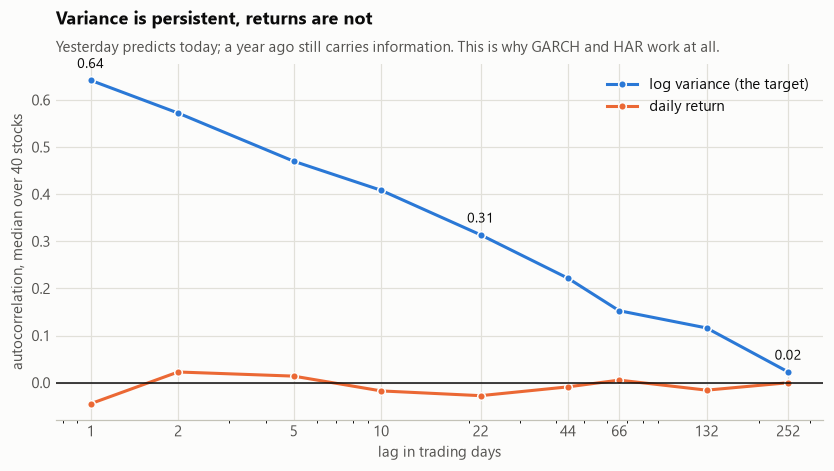

lag (days),1,2,5,10,22,44,66,132,252
log variance,0.64,0.57,0.47,0.41,0.31,0.22,0.15,0.12,0.02
daily return,-0.04,0.02,0.01,-0.02,-0.03,-0.01,0.01,-0.02,-0.00


In [4]:
lags = [1, 2, 5, 10, 22, 44, 66, 132, 252]
acf = pd.DataFrame({L: p.groupby("symbol").log_rv_target.apply(lambda s: s.autocorr(L)) for L in lags})
med_acf = acf.median()
ret_acf = pd.Series({L: p.groupby("symbol").ret.apply(lambda s: s.autocorr(L)).median() for L in lags})
numbers.update(acf1=float(med_acf[1]), acf22=float(med_acf[22]), acf66=float(med_acf[66]),
               acf252=float(med_acf[252]), ret_acf1=float(ret_acf[1]))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(lags, med_acf.values, color=BLUE, lw=2, marker="o", ms=5, markeredgecolor=SURFACE, label="log variance (the target)")
ax.plot(lags, ret_acf.values, color=ORANGE, lw=2, marker="o", ms=5, markeredgecolor=SURFACE, label="daily return")
ax.axhline(0, color=INK, lw=1)
ax.set_xscale("log"); ax.set_xticks(lags); ax.set_xticklabels([str(L) for L in lags])
ax.set_xlabel("lag in trading days", color=MUTED); ax.set_ylabel("autocorrelation, median over 40 stocks", color=MUTED)
for L in (1, 22, 252):
    ax.annotate(f"{med_acf[L]:.2f}", (L, med_acf[L]), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=9)
tidy(ax, "Variance is persistent, returns are not",
     "Yesterday predicts today; a year ago still carries information. This is why GARCH and HAR work at all.")
ax.legend(loc="upper right", frameon=False, labelcolor=INK)
fig.savefig(FIG / "overview_persistence.png", dpi=160, bbox_inches="tight")
plt.show()

pd.DataFrame({"log variance": med_acf, "daily return": ret_acf}).T.round(2).rename_axis(columns="lag (days)")

---
## 4. One market-wide level of risk

The 40 variance series move together. Two ways to see it:

- Standardise each stock's log variance and take the **first principal component**: the share of
  the total variation it explains is the share that one common factor accounts for.
- Correlate each stock's log variance with the **market level** (`mkt_rv`, the realised variance of
  the S&P 500 ETF) and the market level with the **VIX**, the option-implied volatility index.

The chart shows the typical stock's variance over time, as the cross-sectional median smoothed
over 22 days. Four stress episodes stand out; they are the regimes the thesis evaluates separately.

first principal component of the 40 log-variance series explains 58% of their variation
median correlation of a stock's log variance with the market level: 0.75; market level vs VIX: 0.83


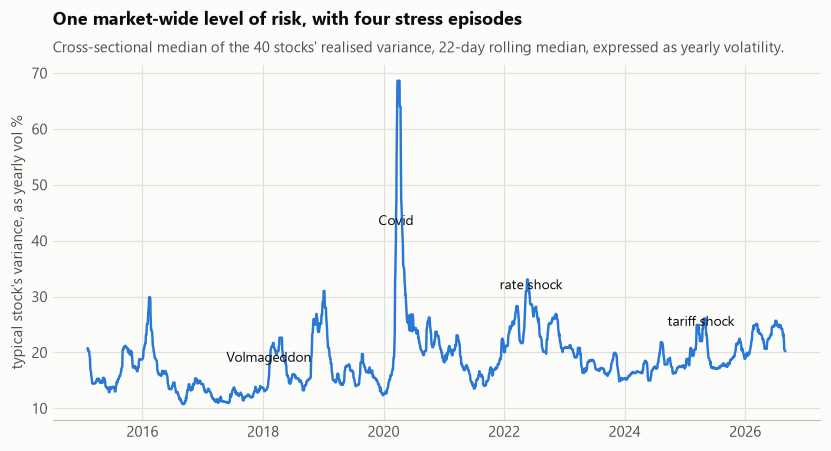

In [5]:
wide = p.pivot(index="date", columns="symbol", values="log_rv_target")
z = (wide - wide.mean()) / wide.std()
eig = np.linalg.eigvalsh(np.cov(z.T.values))[::-1]
share1 = eig[0] / eig.sum()
corr_mkt = p.groupby("symbol").apply(lambda g: np.corrcoef(g.log_rv_target, np.log(g.mkt_rv))[0, 1]).median()
corr_vix = np.corrcoef(np.log(p.groupby("date").mkt_rv.first()), np.log(p.groupby("date").vix.first()))[0, 1]
numbers.update(pc1_share=float(share1), corr_mkt=float(corr_mkt), corr_vix=float(corr_vix))
print(f"first principal component of the 40 log-variance series explains {100 * share1:.0f}% of their variation")
print(f"median correlation of a stock's log variance with the market level: {corr_mkt:.2f}; market level vs VIX: {corr_vix:.2f}")

mkt = p.groupby("date").mkt_rv.first().pipe(ann_vol).rolling(22).median()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(mkt.index, mkt.values, color=BLUE, lw=1.6)
for label, d in [("Volmageddon", "2018-02-05"), ("Covid", "2020-03-16"), ("rate shock", "2022-06-13"), ("tariff shock", "2025-04-08")]:
    d = pd.Timestamp(d)
    ax.annotate(label, (d, mkt.loc[:d].iloc[-1]), xytext=(0, 10), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_ylabel("typical stock's variance, as yearly vol %", color=MUTED)
tidy(ax, "One market-wide level of risk, with four stress episodes",
     "Cross-sectional median of the 40 stocks' realised variance, 22-day rolling median, expressed as yearly volatility.")
fig.savefig(FIG / "overview_market.png", dpi=160, bbox_inches="tight")
plt.show()

---
## 5. The cross-section: calm and wild stocks

Each stock has its own normal level of risk. The dot is the stock's median day, the bar runs from
its 10th to its 90th percentile day. The calmest and the wildest stock differ by a factor of
about three, yet every stock's own bar is wider than that gap: time variation within a stock
matters more than the difference between stocks, which is why the models are fitted per stock
and judged across regimes.

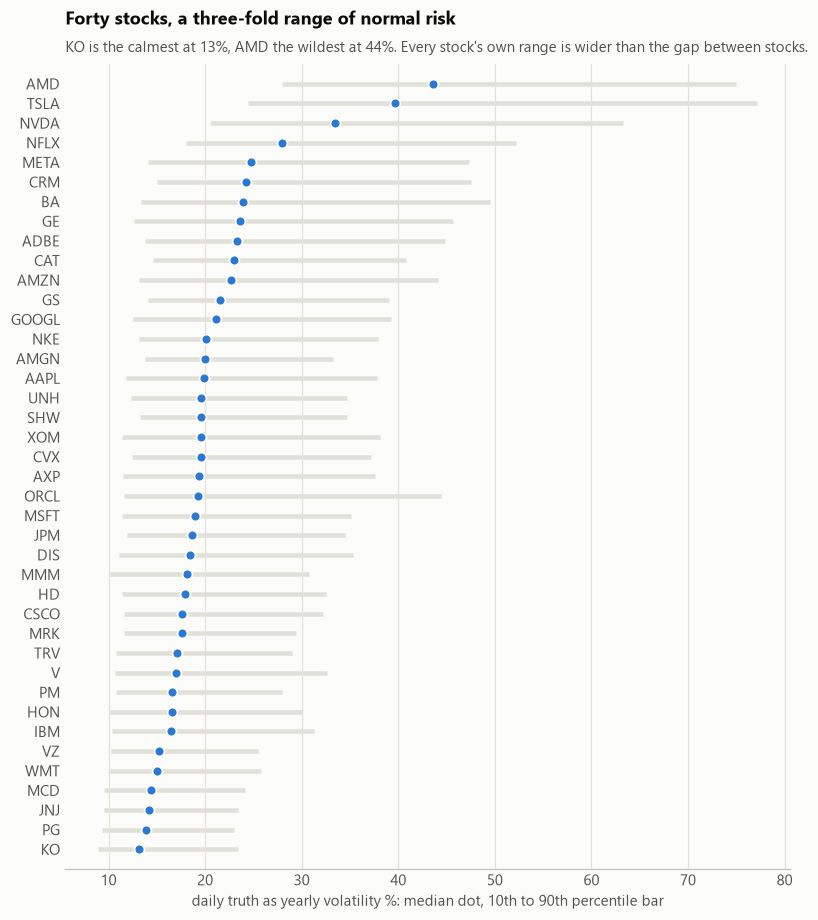

p10  median   p90
             symbol                    
calmest five KO       8.9    13.2  23.4
             PG       9.3    13.9  23.0
             JNJ      9.5    14.2  23.4
             MCD      9.5    14.4  24.2
             WMT     10.1    15.0  25.8
wildest five META    14.1    24.8  47.4
             NFLX    18.1    27.9  52.2
             NVDA    20.5    33.4  63.2
             TSLA    24.4    39.7  77.1
             AMD     27.9    43.6  75.0

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 9.5))
y = np.arange(len(by_stock))
p10 = p.groupby("symbol").rv_target.quantile(0.10).pipe(ann_vol).reindex(by_stock.index)
p90 = p.groupby("symbol").rv_target.quantile(0.90).pipe(ann_vol).reindex(by_stock.index)
ax.hlines(y, p10, p90, color=GRID, lw=3)
ax.scatter(by_stock.values, y, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.set_yticks(y, by_stock.index); ax.set_ylim(-1, len(y))
ax.set_xlabel("daily truth as yearly volatility %: median dot, 10th to 90th percentile bar", color=MUTED)
tidy(ax, "Forty stocks, a three-fold range of normal risk",
     f"{by_stock.index[0]} is the calmest at {by_stock.iloc[0]:.0f}%, {by_stock.index[-1]} the wildest at {by_stock.iloc[-1]:.0f}%. "
     "Every stock's own range is wider than the gap between stocks.")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "overview_cross_section.png", dpi=160, bbox_inches="tight")
plt.show()

cross = pd.DataFrame({"p10": p10, "median": by_stock, "p90": p90}).round(1)
pd.concat([cross.head(5), cross.tail(5)], keys=["calmest five", "wildest five"])

---
## 6. The numbers file

Every number quoted above goes into `notes/figures/data_overview_numbers.json`, so the slides and
the manuscript read the same values this notebook shows.

In [7]:
with open(FIG / "data_overview_numbers.json", "w", encoding="utf-8") as fh:
    json.dump(numbers, fh, indent=1)
print(f"saved {len(numbers)} numbers to {FIG / 'data_overview_numbers.json'}")
pd.Series(numbers, name="value").to_frame()

saved 38 numbers to C:\Users\shoxx\Thesis\notes\figures\data_overview_numbers.json


,value
n_rows,117280
n_stocks,40
n_days,2932
start,2015-01-02
end,2026-08-31
m6_assets,100
m6_start,2022-01-31
m6_end,2023-02-17
m6_rows,26446
m6_teams,251
